# Lab 14-08 · Out-of-Order and Superscalar Execution

Companion to [chapter 14-08](../../chapters/14-08-out-of-order-and-superscalar.md). Programs run on the course's RV32IM simulator; `ooo.py` records every executed instruction and replays the trace through a model of an in-order or out-of-order superscalar core (chapter §3.5). Run the cells in order.

In [1]:
import matplotlib.pyplot as plt
import ooo

inc, _ = ooo.dyn_trace({'i.s': ooo.INC})
ptr, sim_ptr = ooo.dyn_trace({'p.s': ooo.PTR}, ooo.ptr_data())
src, data = ooo.lab_program()
fib, sim_fib = ooo.dyn_trace(src, data)
W = {'unrolled loop (INC)': inc, 'linked list (PTR)': ptr, 'lab program': fib}
print({k: len(t) for k, t in W.items()}, 'list sum', sim_ptr.x[5], 'fib(10)', sim_fib.load(0x104, 4))

{'unrolled loop (INC)': 901, 'linked list (PTR)': 402, 'lab program': 1923} list sum 5050 fib(10) 55


## Part 1 · The dataflow limit

The critical path is the longest chain of true dependences, weighted by latency. A machine with unlimited width and window should finish 2 cycles later: one cycle to dispatch the first instruction, one to retire the last.

In [2]:
for name, tr in W.items():
    n = len(tr)
    cp = ooo.critical_path(tr)
    unl = ooo.schedule(tr, width=n, rob=n)['cycles']
    print(f'{name:22s} N = {n:4d}  critical path = {cp:3d}  unlimited machine = {unl:3d}  IPC limit = {n / cp:.2f}')

unrolled loop (INC)    N =  901  critical path =  69  unlimited machine =  71  IPC limit = 13.06
linked list (PTR)      N =  402  critical path = 302  unlimited machine = 304  IPC limit = 1.33
lab program            N = 1923  critical path = 187  unlimited machine = 189  IPC limit = 10.28


## Part 2 · Width and window

**Predict first:** what IPC does the 8-wide core reach on the linked list? Then sweep the width and the window, in order and out of order.

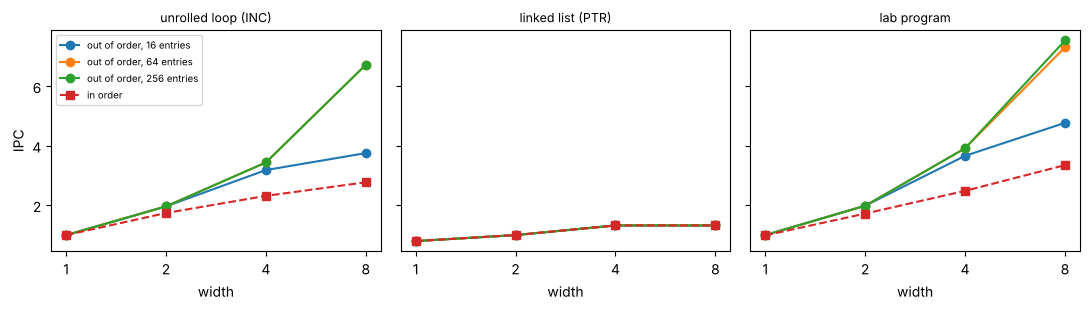

unrolled loop (INC) {1: 905, 2: 459, 4: 262, 8: 134}
linked list (PTR) {1: 505, 2: 403, 4: 304, 8: 304}
lab program {1: 1928, 2: 969, 4: 491, 8: 255}


In [3]:
widths, robs = [1, 2, 4, 8], [16, 64, 256]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, (name, tr) in zip(axes, W.items()):
    for rob in robs:
        ax.plot(widths, [ooo.schedule(tr, width=w, rob=rob)['ipc'] for w in widths], marker='o', label=f'out of order, {rob} entries')
    ax.plot(widths, [ooo.schedule(tr, width=w, rob=256, in_order=True)['ipc'] for w in widths], ls='--', marker='s', label='in order')
    ax.set_xscale('log', base=2); ax.set_xticks(widths, [str(w) for w in widths])
    ax.set_title(name, fontsize=9); ax.set_xlabel('width')
axes[0].set_ylabel('IPC'); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
for name, tr in W.items():
    print(name, {w: ooo.schedule(tr, width=w, rob=256)['cycles'] for w in widths})

The linked list stops at 1.32 from 4-wide on: each address comes from the previous load. The unrolled loop needs both width *and* window: at 8-wide a 16-entry window gives 240 cycles against 134 with 256 entries.

### A closer look: a timeline

`detail=True` returns each instruction's dispatch, issue, completion and retirement cycles. Here are the first 16 instructions of the unrolled loop's main body on the 4-wide core.

In [4]:
d = ooo.schedule(inc, width=4, rob=64, detail=True)
names = {'load': 'lw', 'store': 'sw', 'alu': 'alu', 'branch': 'br', 'mul': 'mul', 'div': 'div'}
print(' i  op   dispatch issue done retire')
for i in range(5, 21):
    print(f'{i:2d}  {names[inc[i][1]]:4s} {d["dispatch"][i]:6d} {d["issue"][i]:6d} {d["done"][i]:4d} {d["retire"][i]:6d}')

 i  op   dispatch issue done retire
 5  lw        1      2    5      5
 6  lw        1      2    5      5
 7  lw        1      2    5      5
 8  lw        2      3    6      6
 9  alu       2      5    6      6
10  alu       2      5    6      6
11  alu       2      5    6      6
12  alu       3      6    7      7
13  sw        3      6    7      7
14  sw        3      6    7      7
15  sw        3      6    7      7
16  sw        4      7    8      8
17  alu       4      5    6      8
18  br        4      7    8      8
19  lw        4      7   10     10
20  lw        5      7   10     10


## Part 3 · Renaming

Without renaming, an instruction must also wait until older readers of its destination have read it (WAR) and older writers have finished (WAW).

In [5]:
for name, tr in W.items():
    on = ooo.schedule(tr, width=8, rob=256)['cycles']
    off = ooo.schedule(tr, width=8, rob=256, rename=False)['cycles']
    print(f'{name:22s} 8-wide: {on:4d} cycles with renaming, {off:4d} without')

unrolled loop (INC)    8-wide:  134 cycles with renaming,  324 without
linked list (PTR)      8-wide:  304 cycles with renaming,  304 without
lab program            8-wide:  255 cycles with renaming,  497 without


## Part 4 · Branch mispredictions

`mispredicted_indices` marks the control transfers that a predictor of Lab 14-07 gets wrong. A mispredicted transfer stops fetch until it resolves, and fetch restarts `refill` cycles later.

In [6]:
mis_g = ooo.mispredicted_indices(fib, direction='gshare', ras_depth=16)
mis_2 = ooo.mispredicted_indices(fib, direction='2bit', ras_depth=16)
print('mispredictions: gshare + RAS', len(mis_g), ' 2-bit + RAS', len(mis_2))
print('perfect prediction, 8-wide:', ooo.schedule(fib, width=8, rob=256)['cycles'])
for refill in (0, 5, 10, 20):
    row = {name: ooo.schedule(fib, width=8, rob=256, mispredicted=m, refill=refill)['cycles'] for name, m in (('gshare', mis_g), ('2-bit', mis_2))}
    print(f'refill {refill:2d}:', row)
print('4-wide in order, gshare, refill 10:', ooo.schedule(fib, width=4, rob=64, in_order=True, mispredicted=mis_g, refill=10)['cycles'])
print('8-wide, no renaming, gshare, refill 10:', ooo.schedule(fib, width=8, rob=256, rename=False, mispredicted=mis_g, refill=10)['cycles'])

mispredictions: gshare + RAS 42  2-bit + RAS 93
perfect prediction, 8-wide: 255
refill  0: {'gshare': 399, '2-bit': 523}
refill  5: {'gshare': 609, '2-bit': 988}


refill 10: {'gshare': 819, '2-bit': 1453}
refill 20: {'gshare': 1239, '2-bit': 2383}
4-wide in order, gshare, refill 10: 1275
8-wide, no renaming, gshare, refill 10: 979


## Part 5 (extension) · Little's law

The divide loop of Problem 14-08.13 needs a large window. Compare the model with the estimate IPC ≈ min(4, W/25), and check Little's law inside the model: average occupancy = IPC × average residence.

In [7]:
dv, _ = ooo.dyn_trace({'d.s': ooo.DIV}, ooo.words(ooo.DIV_VALUES))
for rob in (8, 16, 32, 64, 128, 256):
    r = ooo.schedule(dv, width=4, rob=rob, detail=True)
    res = [r['retire'][i] - r['dispatch'][i] for i in range(len(dv))]
    avg = sum(res) / len(res)
    print(f'W = {rob:3d}: IPC {r["ipc"]:.3f} (estimate {min(4, rob / 25):.2f}), residence {avg:5.1f} cycles, occupancy {sum(res) / r["cycles"]:6.1f} = IPC x residence {r["ipc"] * avg:6.1f}')

W =   8: IPC 0.481 (estimate 0.32), residence  16.6 cycles, occupancy    8.0 = IPC x residence    8.0


W =  16: IPC 0.717 (estimate 0.64), residence  22.2 cycles, occupancy   15.9 = IPC x residence   15.9
W =  32: IPC 1.410 (estimate 1.28), residence  22.2 cycles, occupancy   31.3 = IPC x residence   31.3
W =  64: IPC 2.514 (estimate 2.56), residence  24.2 cycles, occupancy   60.7 = IPC x residence   60.7
W = 128: IPC 3.562 (estimate 4.00), residence  29.6 cycles, occupancy  105.6 = IPC x residence  105.6
W = 256: IPC 3.562 (estimate 4.00), residence  30.0 cycles, occupancy  106.8 = IPC x residence  106.8
